# Exploratory Data Analysis 
---

## General Information

This dataset was generated using the bash script `./mapping_subs.sh`, which retrieves information about subsystems and mailing lists from the kernel files by parsing the `MAINTAINERS` file, using kernel script ```get_maintainer.pl```. The dataset shows, for each kernel file:

- Its **directory** (`directory` column), stored as a string;


- Its **name** (`file` column), stored as a string;


- The **subsystems** it belongs to (`subsystem` column), formatted as a JSON array of strings and stored as a string;


- The **mailing lists** it belongs to (`mailing_list` column), formatted as a JSON array of strings and stored as a string;


- The **maintainers**  it has (`maintainer` column), formatted as a JSON array of objects and stored as a string. Each object contains an `email`, `name` and `role` fields, representing the email and name of the maintainer and the subsystem he maintains, respectively. Both fields are stored as strings.


- The **reviewers**  it has (`reviewer` column), formatted as a JSON array of objects and stored as a string. Each object contains an `email`, `name` and `role` fields, representing the email and name of the reviewer and the subsystem he maintains, respectively. Both fields are stored as strings.
  

- The **relationships between the subsystems and mailing lists** (`list_subsystem`), formatted as a JSON array of objects and stored as a string. Each object contains an `email` and `role` fields, representing the mailing list and its corresponding subsystem, respectively. Both fields are stored as strings.

---

## Imports

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [ ]:
path="../data/results_7.4.0-rc3.csv"
files=pd.read_csv(
    path, 
    converters={"subsystem":json.loads,
                "mailing_list": json.loads,
                "maintainer":json.loads,
                "reviewer":json.loads,
                "list_subsystem": json.loads,
               }
)

pd.set_option("display.max_colwidth", None) #helps visualizing cell info
line='- - - - - - - - - - - - - - - - - - - - - '

## Document reproducibility

In [23]:
import sys, platform, re
from importlib.metadata import version

match=re.search(r'^[^_]*_(.*?)\.csv$', path)
kernel_v=match.group(1)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print(f"Kernel Version:", kernel_v)


for lib in ["pandas", "numpy", "matplotlib", "seaborn"]:
    print(lib, ":", version(lib))

Python: 3.14.6
Platform: Linux-6.12.116+deb13-amd64-x86_64-with-glibc2.41
Kernel Version: 7.4.0-rc3
pandas : 3.0.5
numpy : 2.5.2
matplotlib : 3.11.1
seaborn : 0.13.2


## Initial Data Audit

### General info

In [24]:
display(files.shape)
files.head()

(97371, 7)

,directory,file,subsystem,mailing_list,maintainer,reviewer,list_subsystem
0,.,.clippy.toml,"[RUST, THE REST]","[rust-for-linux@vger.kernel.org, linux-kernel@vger.kernel.org]","[{'email': 'ojeda@kernel.org', 'name': 'Miguel Ojeda', 'role': 'maintainer:RUST'}]","[{'email': 'boqun@kernel.org', 'name': 'Boqun Feng', 'role': 'reviewer:RUST'}, {'email': 'gary@garyguo.net', 'name': 'Gary Guo', 'role': 'reviewer:RUST'}, {'email': 'bjorn3_gh@protonmail.com', 'name': '""BjÃ¶rn Roy Baron""', 'role': 'reviewer:RUST'}, {'email': 'lossin@kernel.org', 'name': 'Benno Lossin', 'role': 'reviewer:RUST'}, {'email': 'a.hindborg@kernel.org', 'name': 'Andreas Hindborg', 'role': 'reviewer:RUST'}, {'email': 'aliceryhl@google.com', 'name': 'Alice Ryhl', 'role': 'reviewer:RUST'}, {'email': 'tmgross@umich.edu', 'name': 'Trevor Gross', 'role': 'reviewer:RUST'}, {'email': 'dakr@kernel.org', 'name': 'Danilo Krummrich', 'role': 'reviewer:RUST'}, {'email': 'daniel.almeida@collabora.com', 'name': 'Daniel Almeida', 'role': 'reviewer:RUST'}, {'email': 'tamird@kernel.org', 'name': 'Tamir Duberstein', 'role': 'reviewer:RUST'}, {'email': 'acourbot@nvidia.com', 'name': 'Alexandre Courbot', 'role': 'reviewer:RUST'}, {'email': 'work@onurozkan.dev', 'name': '""Onur Ãzkan""', 'role': 'reviewer:RUST'}]","[{'email': 'rust-for-linux@vger.kernel.org', 'role': 'open list:RUST'}, {'email': 'linux-kernel@vger.kernel.org', 'role': 'open list'}]"
1,.,.get_maintainer.ignore,[THE REST],[linux-kernel@vger.kernel.org],[],[],"[{'email': 'linux-kernel@vger.kernel.org', 'role': 'open list'}]"
2,.,AGENTS.md,[THE REST],[linux-kernel@vger.kernel.org],[],[],"[{'email': 'linux-kernel@vger.kernel.org', 'role': 'open list'}]"
3,.,.rustfmt.toml,"[RUST, THE REST]","[rust-for-linux@vger.kernel.org, linux-kernel@vger.kernel.org]","[{'email': 'ojeda@kernel.org', 'name': 'Miguel Ojeda', 'role': 'maintainer:RUST'}]","[{'email': 'boqun@kernel.org', 'name': 'Boqun Feng', 'role': 'reviewer:RUST'}, {'email': 'gary@garyguo.net', 'name': 'Gary Guo', 'role': 'reviewer:RUST'}, {'email': 'bjorn3_gh@protonmail.com', 'name': '""BjÃ¶rn Roy Baron""', 'role': 'reviewer:RUST'}, {'email': 'lossin@kernel.org', 'name': 'Benno Lossin', 'role': 'reviewer:RUST'}, {'email': 'a.hindborg@kernel.org', 'name': 'Andreas Hindborg', 'role': 'reviewer:RUST'}, {'email': 'aliceryhl@google.com', 'name': 'Alice Ryhl', 'role': 'reviewer:RUST'}, {'email': 'tmgross@umich.edu', 'name': 'Trevor Gross', 'role': 'reviewer:RUST'}, {'email': 'dakr@kernel.org', 'name': 'Danilo Krummrich', 'role': 'reviewer:RUST'}, {'email': 'daniel.almeida@collabora.com', 'name': 'Daniel Almeida', 'role': 'reviewer:RUST'}, {'email': 'tamird@kernel.org', 'name': 'Tamir Duberstein', 'role': 'reviewer:RUST'}, {'email': 'acourbot@nvidia.com', 'name': 'Alexandre Courbot', 'role': 'reviewer:RUST'}, {'email': 'work@onurozkan.dev', 'name': '""Onur Ãzkan""', 'role': 'reviewer:RUST'}]","[{'email': 'rust-for-linux@vger.kernel.org', 'role': 'open list:RUST'}, {'email': 'linux-kernel@vger.kernel.org', 'role': 'open list'}]"
4,.,.gitattributes,[THE REST],[linux-kernel@vger.kernel.org],[],[],"[{'email': 'linux-kernel@vger.kernel.org', 'role': 'open list'}]"


In [25]:
files.info()

<class 'pandas.DataFrame'>
RangeIndex: 97371 entries, 0 to 97370
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   directory       97371 non-null  str   
 1   file            97371 non-null  str   
 2   subsystem       97371 non-null  object
 3   mailing_list    97371 non-null  object
 4   maintainer      97371 non-null  object
 5   reviewer        97371 non-null  object
 6   list_subsystem  97371 non-null  object
dtypes: object(5), str(2)
memory usage: 5.2+ MB


### Columns treatment

#### add new columns and save original dataset

In [26]:
original_df = files.copy()

#create a full path column
files['path']=files['directory']+'/'+files['file']
files['path']=files['path'].str.removeprefix('./')

#create an index for each file
files=files.reset_index(drop=True)
files['file_id']=files.index

#gets the number of subsystems
files['n_subsystem']=files['subsystem'].map(len , na_action='ignore')

#gets the number of mailing lists
files['n_mailing_list']=files['mailing_list'].map(len , na_action='ignore')

#gets the number of maintainers
files['n_maintainer']=files['maintainer'].map(len, na_action='ignore')

#gets the number of reviewers
files['n_reviewer']=files['reviewer'].map(len, na_action='ignore')

#### Create aditional datasets

##### `file_list`

Create an auxiliar database `file_list` with 3 columns: `file_id`, `subsystem` and `mailing_list`, in which each row represents a subsystem and its corresponding mailing list associated with a file specified by the `file_id` field. 

In [27]:
file_list=(files[['file_id', 'list_subsystem']]
                .explode('list_subsystem')
                .dropna(subset=['list_subsystem'])
                .reset_index(drop=True)
            )

#get the subsystem name
file_list['subsystem']=(file_list['list_subsystem']
                            .str.get('role')
                            .str.replace(r'^[^:]+:?', '', regex=True)
                            .replace('', 'THE REST')
                        )

#get the mailing list
file_list['mailing_list']=file_list['list_subsystem'].str.get('email')

file_list=file_list.drop(columns=['list_subsystem'])

#to improve execution speed
file_list['subsystem'] = file_list['subsystem'].astype('category')
file_list['mailing_list'] = file_list['mailing_list'].astype('category')

display(file_list.isna().sum())
file_list.head()

file_id         0
subsystem       0
mailing_list    0
dtype: int64

,file_id,subsystem,mailing_list
0,0,RUST,rust-for-linux@vger.kernel.org
1,0,THE REST,linux-kernel@vger.kernel.org
2,1,THE REST,linux-kernel@vger.kernel.org
3,2,THE REST,linux-kernel@vger.kernel.org
4,3,RUST,rust-for-linux@vger.kernel.org


##### `file_people`

Create an auxiliar database `file_list` with 3 columns: `file_id`, `subsystem` and `mailing_list`, in which each row represents a subsystem and its corresponding mailing list, associated with a file specified by the `file_id` field. 

In [28]:
#auxiliar function to extract maintainers and reviewers
def extract_people(df, col):
    temp=(df[['file_id', col]]
            .explode(col)
            .dropna(subset=[col])
            .reset_index(drop=True)
    )

    #add the maintainer/reviewer name, with the right encoding
    temp['name']=(
        temp[col]
        .str.get('name')
        .str.strip('"')
        .str.encode('latin1',)
        .str.decode('UTF-8')
    )

    #add the maintainer/reviewer email
    temp['email']=temp[col].str.get('email')

    #add the maintainer/reviewer role ans subsystem
    role_subsystem=temp[col].str.get('role').str.split(':', n=1, expand=True)

    temp['role']=role_subsystem[0].str.strip().astype('category')
    temp['subsystem']=role_subsystem[1].fillna('THE REST').str.strip().astype('category')
    
    return temp[['file_id', 'name', 'email', 'role', 'subsystem']]

file_people=pd.concat(
    [extract_people(files, 'maintainer'), extract_people(files, 'reviewer')],
    ignore_index=True
)

print(file_people.shape)
file_people.head()

(463176, 5)


,file_id,name,email,role,subsystem
0,0,Miguel Ojeda,ojeda@kernel.org,maintainer,RUST
1,3,Miguel Ojeda,ojeda@kernel.org,maintainer,RUST
2,6,Miguel Ojeda,ojeda@kernel.org,maintainer,CLANG-FORMAT FILE
3,11,Thomas Gleixner,tglx@kernel.org,maintainer,LICENSES and SPDX stuff
4,11,Greg Kroah-Hartman,gregkh@linuxfoundation.org,maintainer,LICENSES and SPDX stuff


#####
Delete unnecessary columns from `files` and change `subsystem` and `mailing_list`just to help visualization

In [29]:
files=files.drop(columns=['maintainer', 'reviewer', 'list_subsystem'])

In [30]:
files['subsystem']=files['subsystem'].apply(lambda x: ' | '.join(x))
files['mailing_list']=files['mailing_list'].apply(lambda x: ' | '.join(x))

In [31]:
display(files)
print(line)
display(file_list)
print(line)
display(file_people)

,directory,file,subsystem,mailing_list,path,file_id,n_subsystem,n_mailing_list,n_maintainer,n_reviewer
0,.,.clippy.toml,RUST | THE REST,rust-for-linux@vger.kernel.org | linux-kernel@vger.kernel.org,.clippy.toml,0,2,2,1,12
1,.,.get_maintainer.ignore,THE REST,linux-kernel@vger.kernel.org,.get_maintainer.ignore,1,1,1,0,0
2,.,AGENTS.md,THE REST,linux-kernel@vger.kernel.org,AGENTS.md,2,1,1,0,0
3,.,.rustfmt.toml,RUST | THE REST,rust-for-linux@vger.kernel.org | linux-kernel@vger.kernel.org,.rustfmt.toml,3,2,2,1,12
4,.,.gitattributes,THE REST,linux-kernel@vger.kernel.org,.gitattributes,4,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...
97366,virt/kvm,vfio.c,KERNEL VIRTUAL MACHINE (KVM) | THE REST,kvm@vger.kernel.org | linux-kernel@vger.kernel.org,virt/kvm/vfio.c,97366,2,2,1,1
97367,virt/kvm,kvm_main.c,KERNEL VIRTUAL MACHINE (KVM) | THE REST,kvm@vger.kernel.org | linux-kernel@vger.kernel.org,virt/kvm/kvm_main.c,97367,2,2,1,1
97368,virt/lib,Kconfig,VIRT LIB | THE REST,kvm@vger.kernel.org | linux-kernel@vger.kernel.org,virt/lib/Kconfig,97368,2,2,2,0
97369,virt/lib,irqbypass.c,VIRT LIB | THE REST,kvm@vger.kernel.org | linux-kernel@vger.kernel.org,virt/lib/irqbypass.c,97369,2,2,2,0


- - - - - - - - - - - - - - - - - - - - - 


,file_id,subsystem,mailing_list
0,0,RUST,rust-for-linux@vger.kernel.org
1,0,THE REST,linux-kernel@vger.kernel.org
2,1,THE REST,linux-kernel@vger.kernel.org
3,2,THE REST,linux-kernel@vger.kernel.org
4,3,RUST,rust-for-linux@vger.kernel.org
...,...,...,...
227281,97368,THE REST,linux-kernel@vger.kernel.org
227282,97369,VIRT LIB,kvm@vger.kernel.org
227283,97369,THE REST,linux-kernel@vger.kernel.org
227284,97370,VIRT LIB,kvm@vger.kernel.org


- - - - - - - - - - - - - - - - - - - - - 


,file_id,name,email,role,subsystem
0,0,Miguel Ojeda,ojeda@kernel.org,maintainer,RUST
1,3,Miguel Ojeda,ojeda@kernel.org,maintainer,RUST
2,6,Miguel Ojeda,ojeda@kernel.org,maintainer,CLANG-FORMAT FILE
3,11,Thomas Gleixner,tglx@kernel.org,maintainer,LICENSES and SPDX stuff
4,11,Greg Kroah-Hartman,gregkh@linuxfoundation.org,maintainer,LICENSES and SPDX stuff
...,...,...,...,...,...
463171,97363,Sean Christopherson,seanjc@google.com,reviewer,KERNEL VIRTUAL MACHINE (KVM)
463172,97364,Sean Christopherson,seanjc@google.com,reviewer,KERNEL VIRTUAL MACHINE (KVM)
463173,97365,Sean Christopherson,seanjc@google.com,reviewer,KERNEL VIRTUAL MACHINE (KVM)
463174,97366,Sean Christopherson,seanjc@google.com,reviewer,KERNEL VIRTUAL MACHINE (KVM)


## Data exploring


In [32]:
display(files.describe())

total_files = files.shape[0]
the_rest_files = file_list[file_list['subsystem'] == 'THE REST']['file_id'].nunique()

print('Number of files:')
print(total_files)

print('Number of files in \'THE REST\' subsystem:')
print(the_rest_files)

print('diff: ',total_files-the_rest_files)

,file_id,n_subsystem,n_mailing_list,n_maintainer,n_reviewer
count,97371.000000,97371.000000,97371.000000,97371.000000,97371.000000
mean,48685.000000,2.863830,2.334227,3.660197,1.096620
std,28108.730868,0.908404,0.726901,2.261488,1.958816
min,0.000000,1.000000,1.000000,0.000000,0.000000
25%,24342.500000,2.000000,2.000000,2.000000,0.000000
50%,48685.000000,3.000000,2.000000,4.000000,0.000000
75%,73027.500000,3.000000,3.000000,5.000000,1.000000
max,97370.000000,7.000000,6.000000,14.000000,18.000000


Number of files:
97371
Number of files in 'THE REST' subsystem:
87372
diff:  9999


## Investigating files not included in 'THE REST'

In [33]:
ids_the_rest = file_list[file_list['subsystem'] == 'THE REST']['file_id']
out_the_rest = files[~files['file_id'].isin(ids_the_rest)].copy()

display(out_the_rest[['file_id', 'path', 'subsystem', 'mailing_list']])

display(original_df.iloc[67])

,file_id,path,subsystem,mailing_list
67,67,Documentation/ABI/stable/sysfs-bus-fsl-mc,QORIQ DPAA2 FSL-MC BUS DRIVER | THE REST,linuxppc-dev@lists.ozlabs.org | linux-kernel@vger.kernel.org
207,207,Documentation/ABI/testing/sysfs-block-zram,ZRAM COMPRESSED RAM BLOCK DEVICE DRVIER | THE REST,linux-kernel@vger.kernel.org
237,237,Documentation/ABI/testing/sysfs-bus-event_source-devices-hisi_ptt,HISILICON PTT DRIVER | THE REST,linux-kernel@vger.kernel.org
273,273,Documentation/ABI/testing/sysfs-bus-iio-adc-mt6360,IIO SUBSYSTEM AND DRIVERS | ARM/Mediatek SoC support | THE REST,linux-iio@vger.kernel.org | linux-kernel@vger.kernel.org
474,474,Documentation/ABI/testing/sysfs-class-zram,ZRAM COMPRESSED RAM BLOCK DEVICE DRVIER | THE REST,linux-kernel@vger.kernel.org
...,...,...,...,...
97062,97062,tools/tracing/rtla/tests/unit/osnoise_top_cli.c,Real-time Linux Analysis (RTLA) tools | THE REST,linux-trace-kernel@vger.kernel.org | linux-kernel@vger.kernel.org
97063,97063,tools/tracing/rtla/tests/unit/timerlat_hist_cli.c,Real-time Linux Analysis (RTLA) tools | THE REST,linux-trace-kernel@vger.kernel.org | linux-kernel@vger.kernel.org
97064,97064,tools/tracing/rtla/tests/unit/timerlat_top_cli.c,Real-time Linux Analysis (RTLA) tools | THE REST,linux-trace-kernel@vger.kernel.org | linux-kernel@vger.kernel.org
97065,97065,tools/tracing/rtla/tests/unit/unit_tests.c,Real-time Linux Analysis (RTLA) tools | THE REST,linux-trace-kernel@vger.kernel.org | linux-kernel@vger.kernel.org


directory                                                                                                                                                                              Documentation/ABI/stable
file                                                                                                                                                                                           sysfs-bus-fsl-mc
subsystem                                                                                                                                                             [QORIQ DPAA2 FSL-MC BUS DRIVER, THE REST]
mailing_list                                                                                                                                      [linuxppc-dev@lists.ozlabs.org, linux-kernel@vger.kernel.org]
maintainer                                                                                    [{'email': 'ioana.ciornei@nxp.com', 'name': 'Ioana Ciornei', 'role': 'main

In [34]:
display(file_list[file_list['file_id'].isin([67, 207])])
print("Com strip:", file_list[file_list['subsystem'].str.strip() == 'THE REST']['file_id'].nunique())

,file_id,subsystem,mailing_list
79,67,QORIQ DPAA2 FSL-MC BUS DRIVER,linuxppc-dev@lists.ozlabs.org
80,67,QORIQ DPAA2 FSL-MC BUS DRIVER,linux-kernel@vger.kernel.org
277,207,ZRAM COMPRESSED RAM BLOCK DEVICE DRVIER,linux-kernel@vger.kernel.org


Com strip: 87372


### Plots

Text(0.5, 0, 'Number of Reviewers')

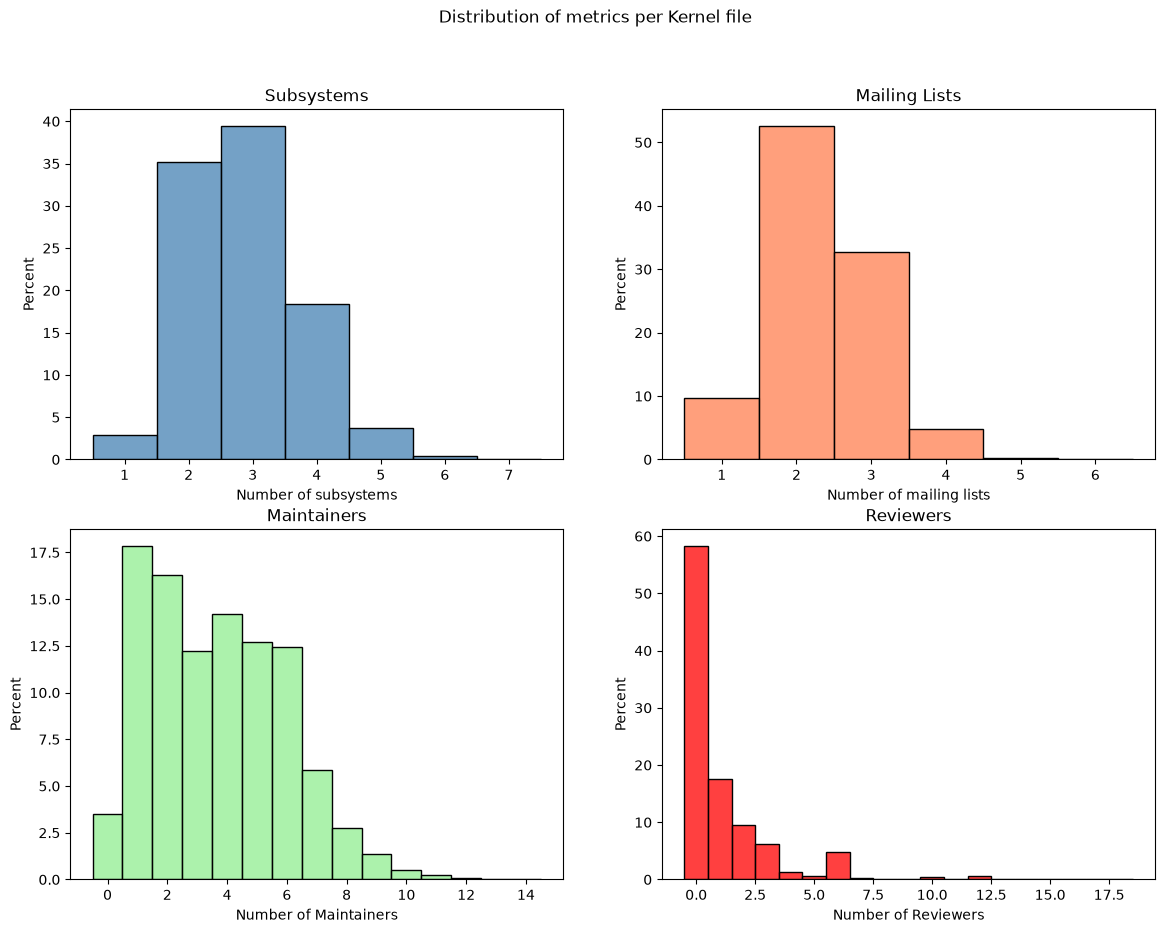

In [35]:
fig, axis = plt.subplots(2, 2, figsize=(14, 10))
ax=axis.flatten()

fig.suptitle("Distribution of metrics per Kernel file")

#plot number of subsystems per file
sns.histplot(
    data=files,
    x='n_subsystem',
    stat='percent',
    discrete=True,
    ax=ax[0], 
    color='steelblue'
)

ax[0].set_title('Subsystems')
ax[0].set_xlabel("Number of subsystems")

#plot number of mailing lists per file
sns.histplot(
    data=files,
    x='n_mailing_list',
    stat='percent',
    discrete=True,
    ax=ax[1], 
    color='coral'
)

ax[1].set_title('Mailing Lists')
ax[1].set_xlabel("Number of mailing lists")

#plot number of subsystems per file
sns.histplot(
    data=files,
    x='n_maintainer',
    stat='percent',
    discrete=True,
    ax=ax[2], 
    color='lightgreen'
)
ax[2].set_title('Maintainers')
ax[2].set_xlabel("Number of Maintainers")

#plot number of mailing lists per file
sns.histplot(
    data=files,
    x='n_reviewer',
    stat='percent',
    discrete=True,
    ax=ax[3], 
    color='red'
)
ax[3].set_title('Reviewers')
ax[3].set_xlabel("Number of Reviewers")

In [36]:
#filter to get just the subsystems without the 'THE REST' subsystem
subsystem=file_list['subsystem'][file_list['subsystem'] != 'THE REST']
